In [ ]:
!nvidia-smi

Sun Oct 11 21:59:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Install Google Drive download utility
!pip -q install gdown

# Create dataset directory
!mkdir -p /content/data

# Download the squirrel dataset
!gdown "https://drive.google.com/uc?id=1WWIY89soGJR2hDTC6zQyS0NiTU_e5AgV" -O /content/data/squirrel-v2-audited-coco.zip

# Check downloaded file size
!ls -lh /content/data/squirrel-v2-audited-coco.zip

Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1WWIY89soGJR2hDTC6zQyS0NiTU_e5AgV

but Gdown can't. Please check connections and permissions.
ls: cannot access '/content/data/squirrel-v2-audited-coco.zip': No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# List files in your Google Drive
files = os.listdir('/content/drive/MyDrive')
print(files)

['Colab Notebooks', 'Md Abu Bakar.jpeg', 'Tamim Bhai Glacier', 'Report 6.docx', 'Report 6.gdoc', 'CITI Certificate.pdf', 'CITI Completion Report.pdf', 'Graphical Perception Theory.pdf', 'Group Domain Analysis.drawio.pdf', 'Interaction presentation.gslides', 'q1_summary.pdf', 'q3_summary.pdf', 'Mail draft.docx', 'My Courses', 'D3 Project.zip', 'RIT.zip', 'Google Meet', 'squirrel-v2-audited-coco.zip']


In [ ]:
import os
import zipfile

dataset_path = '/content/drive/MyDrive/squirrel-v2-audited-coco.zip'

print("File accessible:", os.path.isfile(dataset_path))

if os.path.isfile(dataset_path):
    size_gb = os.path.getsize(dataset_path) / (1024 ** 3)
    print(f"File size: {size_gb:.2f} GB")
    print("Valid ZIP:", zipfile.is_zipfile(dataset_path))

File accessible: True
File size: 2.89 GB
Valid ZIP: True


In [ ]:
# Create a folder for the dataset
!mkdir -p /content/data

# Extract the ZIP file
!unzip -q "/content/drive/MyDrive/squirrel-v2-audited-coco.zip" -d /content/data

# Show the extracted files and folders
!ls -lh /content/data

total 4.0K
drwxrwxr-x 5 root root 4.0K Sep 26 14:25 squirrel-v2-audited-coco


In [ ]:
import json
from pathlib import Path

dataset_dir = Path("/content/data/squirrel-v2-audited-coco")

for split in ["train", "valid", "test"]:
    annotation_file = dataset_dir / split / "_annotations.coco.json"

    with open(annotation_file, "r") as f:
        data = json.load(f)

    print(f"{split}: {len(data['images'])} images, "
          f"{len(data['annotations'])} bounding boxes")

    print(f"Classes: {len(data['categories'])}")
    print("-------------------------")

train: 5988 images, 6379 bounding boxes
Classes: 11
-------------------------
valid: 1282 images, 1350 bounding boxes
Classes: 11
-------------------------
test: 1284 images, 1380 bounding boxes
Classes: 11
-------------------------


In [ ]:
# Go to the main Colab directory
%cd /content

# Download the original YOLOv5 repository
!git clone https://github.com/ultralytics/yolov5.git

# Enter the YOLOv5 folder
%cd /content/yolov5

# Install required Python libraries
!pip install -q -r requirements.txt

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (331/331), done.
remote: Compressing objects: 100% (194/194), done.
remote: Total 18770 (delta 270), reused 137 (delta 137), pack-reused 18439 (from 5)
Receiving objects: 100% (18770/18770), 17.80 MiB | 20.34 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.9 MB/s eta 0:00:00


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import json

annotation_path = "/content/data/squirrel-v2-audited-coco/train/_annotations.coco.json"

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

categories = sorted(coco_data["categories"], key=lambda x: x["id"])

for i, category in enumerate(categories):
    print(f"YOLO Class {i}: {category['name']} (COCO ID: {category['id']})")

YOLO Class 0: Callosciurus erythraeus (COCO ID: 1)
YOLO Class 1: Sciurus aureogaster (COCO ID: 2)
YOLO Class 2: Sciurus carolinensis (COCO ID: 3)
YOLO Class 3: Sciurus granatensis (COCO ID: 4)
YOLO Class 4: Sciurus griseus (COCO ID: 5)
YOLO Class 5: Sciurus lis (COCO ID: 6)
YOLO Class 6: Sciurus niger (COCO ID: 7)
YOLO Class 7: Sciurus vulgaris (COCO ID: 8)
YOLO Class 8: Tamiasciurus douglasii (COCO ID: 9)
YOLO Class 9: Tamiasciurus hudsonicus (COCO ID: 10)
YOLO Class 10: generic_squirrel (COCO ID: 11)


In [ ]:
import json
from pathlib import Path
from collections import defaultdict

source = Path("/content/data/squirrel-v2-audited-coco")
output = Path("/content/squirrel-yolo")

for split in ["train", "valid", "test"]:

    # Load COCO annotations
    with open(source / split / "_annotations.coco.json") as f:
        coco = json.load(f)

    # Map COCO class IDs to YOLO class IDs
    categories = sorted(coco["categories"], key=lambda c: c["id"])
    class_map = {c["id"]: i for i, c in enumerate(categories)}

    # Prepare image and label folders
    image_dir = output / "images" / split
    label_dir = output / "labels" / split

    image_dir.parent.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    # Link original images without copying them
    if not image_dir.exists():
        image_dir.symlink_to(source / split, target_is_directory=True)

    images = {img["id"]: img for img in coco["images"]}
    labels = defaultdict(list)

    for ann in coco["annotations"]:
        img = images[ann["image_id"]]

        W, H = img["width"], img["height"]
        x, y, w, h = ann["bbox"]

        # Check bounding-box validity
        if not (W > 0 and H > 0 and w > 0 and h > 0
                and x >= 0 and y >= 0
                and x + w <= W + 0.001
                and y + h <= H + 0.001):
            raise ValueError(f"Invalid bounding box: {ann['id']}")

        class_id = class_map[ann["category_id"]]

        # Convert to normalized YOLO coordinates
        xc = (x + w / 2) / W
        yc = (y + h / 2) / H
        nw = w / W
        nh = h / H

        labels[ann["image_id"]].append(
            f"{class_id} {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}"
        )

    # Save one label file per image
    for img in coco["images"]:
        filename = Path(img["file_name"])
        if not (source / split / filename).is_file():
            raise FileNotFoundError(filename)

        label_file = label_dir / (filename.stem + ".txt")
        label_file.write_text(
            "\n".join(labels[img["id"]]) +
            ("\n" if labels[img["id"]] else "")
        )

    print(f"{split}: {len(coco['images'])} images converted")

print("COCO to YOLO conversion completed!")

train: 5988 images converted
valid: 1282 images converted
test: 1284 images converted
COCO to YOLO conversion completed!


In [ ]:
import json
import yaml
from pathlib import Path

# Read the class names from the original annotations
with open("/content/data/squirrel-v2-audited-coco/train/_annotations.coco.json") as f:
    coco = json.load(f)

categories = sorted(coco["categories"], key=lambda c: c["id"])
class_names = [c["name"] for c in categories]

# Create YOLOv5 dataset configuration
config = {
    "path": "/content/squirrel-yolo",
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

# Save data.yaml
yaml_path = "/content/squirrel-yolo/data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("data.yaml created successfully!")
print("Number of classes:", len(class_names))
print("Location:", yaml_path)

data.yaml created successfully!
Number of classes: 11
Location: /content/squirrel-yolo/data.yaml


In [ ]:
from pathlib import Path

base = Path("/content/squirrel-yolo")

for split in ["train", "valid", "test"]:
    image_dir = base / "images" / split
    label_dir = base / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    missing = [
        p.name for p in images
        if not (label_dir / (p.stem + ".txt")).is_file()
    ]

    print(f"{split}: {len(images)} images")
    print(f"Missing label files: {len(missing)}")
    print("-------------------------")

train: 5988 images
Missing label files: 0
-------------------------
valid: 1282 images
Missing label files: 0
-------------------------
test: 1284 images
Missing label files: 0
-------------------------


In [ ]:
from pathlib import Path

base = Path("/content/squirrel-yolo/labels")
total_boxes = 0
invalid_boxes = 0

for split in ["train", "valid", "test"]:
    for label_file in (base / split).glob("*.txt"):
        for line in label_file.read_text().splitlines():
            values = list(map(float, line.split()))

            if len(values) != 5:
                invalid_boxes += 1
                continue

            cls, x, y, w, h = values

            if not (
                cls.is_integer() and 0 <= cls < 11
                and 0 < w <= 1 and 0 < h <= 1
                and w / 2 <= x <= 1 - w / 2
                and h / 2 <= y <= 1 - h / 2
            ):
                invalid_boxes += 1

            total_boxes += 1

print("Total bounding boxes:", total_boxes)
print("Invalid bounding boxes:", invalid_boxes)

Total bounding boxes: 9109
Invalid bounding boxes: 62


In [ ]:
from pathlib import Path

label_dir = Path("/content/squirrel-yolo/labels")

tolerance = 1e-6
invalid_count = 0
examples = []

for file in label_dir.rglob("*.txt"):
    for line in file.read_text().splitlines():
        values = list(map(float, line.split()))

        if len(values) != 5:
            invalid_count += 1
            continue

        cls, x, y, w, h = values

        valid = (
            cls.is_integer() and 0 <= cls < 11
            and w > 0 and h > 0
            and w <= 1 + tolerance
            and h <= 1 + tolerance
            and x - w/2 >= -tolerance
            and x + w/2 <= 1 + tolerance
            and y - h/2 >= -tolerance
            and y + h/2 <= 1 + tolerance
        )

        if not valid:
            invalid_count += 1
            if len(examples) < 5:
                examples.append((file.name, values))

print("Invalid boxes after rounding tolerance:", invalid_count)
print("Examples:", examples)

Invalid boxes after rounding tolerance: 0
Examples: []


In [ ]:
%cd /content/yolov5

from utils.downloads import attempt_download

weights_path = attempt_download("yolov5m.pt")

print("Pretrained model downloaded:", weights_path)

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


100%|██████████| 40.8M/40.8M [00:01<00:00, 29.1MB/s]


Pretrained model downloaded: yolov5m.pt


In [ ]:
%cd /content/yolov5

!python train.py \
    --img 640 \
    --batch-size 8 \
    --epochs 3 \
    --data /content/squirrel-yolo/data.yaml \
    --weights yolov5m.pt \
    --device 0 \
    --workers 2 \
    --project /content/drive/MyDrive/YOLOv5_Squirrel_Training \
    --name squirrel_3epochs \
    --save-period 1 \
    --exist-ok

/content/yolov5
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791761563.786486   16715 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5m.pt, cfg=, data=/content/squirrel-yolo/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=3, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, wo

In [ ]:
from pathlib import Path
import os
import shutil

source = Path("/content/data/squirrel-v2-audited-coco")
output = Path("/content/squirrel-yolo")

for split in ["train", "valid", "test"]:
    image_dir = output / "images" / split
    label_dir = output / "labels" / split

    # Remove the folder shortcut, not the original images
    if image_dir.is_symlink():
        image_dir.unlink()

    image_dir.mkdir(parents=True, exist_ok=True)

    # Create direct file links to the original images
    for image in (source / split).iterdir():
        if image.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        destination = image_dir / image.name

        if not destination.exists():
            try:
                os.link(image, destination)
            except OSError:
                shutil.copy2(image, destination)

    # Verify image-to-label matching
    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    missing = sum(
        not (label_dir / f"{p.stem}.txt").is_file()
        for p in images
    )

    print(f"{split}: {len(images)} images, {missing} missing labels")

print("Folder structure fixed!")

train: 5988 images, 0 missing labels
valid: 1282 images, 0 missing labels
test: 1284 images, 0 missing labels
Folder structure fixed!


In [ ]:
%cd /content/yolov5

!WANDB_MODE=disabled python train.py \
    --img 640 \
    --batch-size 8 \
    --epochs 3 \
    --data /content/squirrel-yolo/data.yaml \
    --weights yolov5m.pt \
    --device 0 \
    --workers 2 \
    --project /content/drive/MyDrive/YOLOv5_Squirrel_Training \
    --name squirrel_3epochs_retry \
    --save-period 1

/content/yolov5
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791761892.371939   18168 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5m.pt, cfg=, data=/content/squirrel-yolo/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=3, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=/content/drive/MyDrive/YOLOv5_Squirrel_Training, name=squirrel_3epochs_retry, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up 

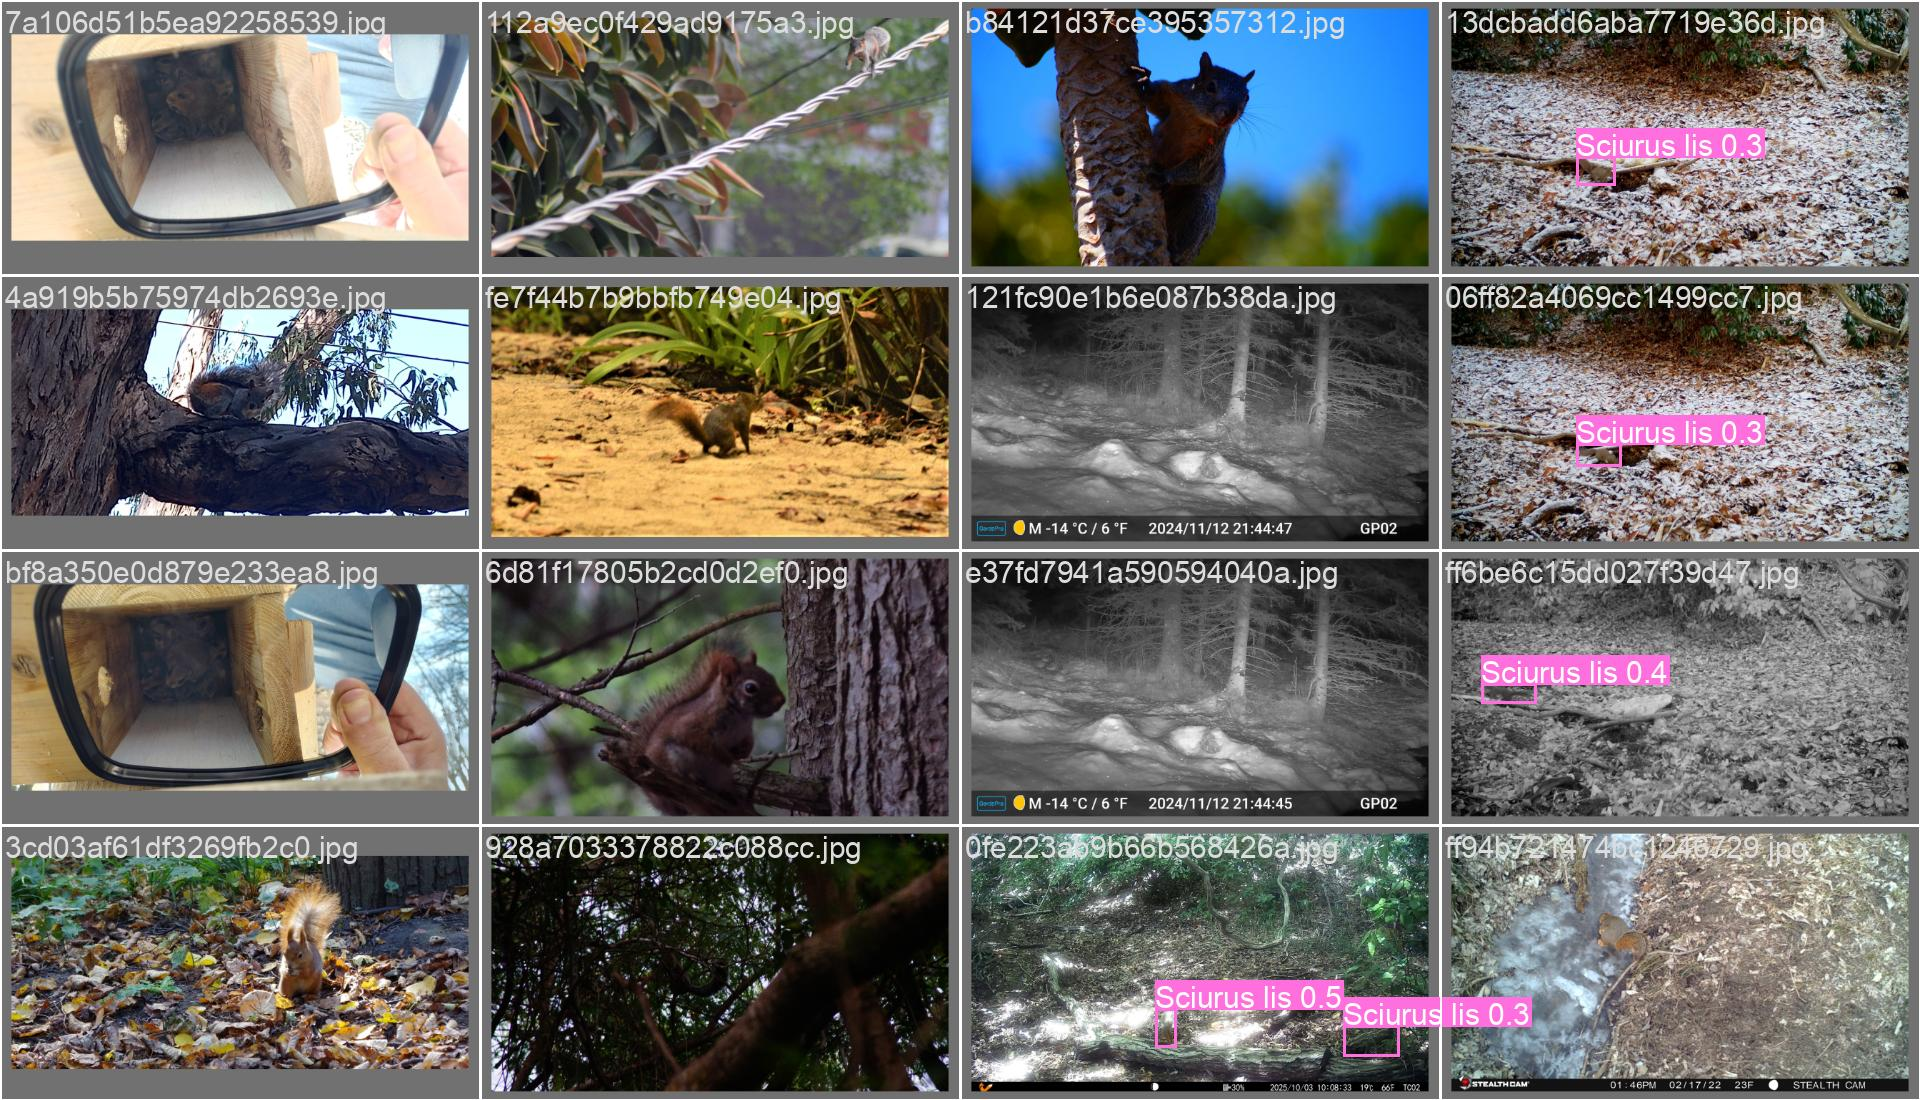

In [ ]:
from pathlib import Path
from IPython.display import display, Image

run_dir = Path(
    "/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_3epochs_retry"
)

prediction_image = run_dir / "val_batch0_pred.jpg"

if prediction_image.exists():
    display(Image(filename=str(prediction_image), width=850))
else:
    print("Prediction image not found.")
    print("Available images:", [p.name for p in run_dir.glob("*.jpg")])

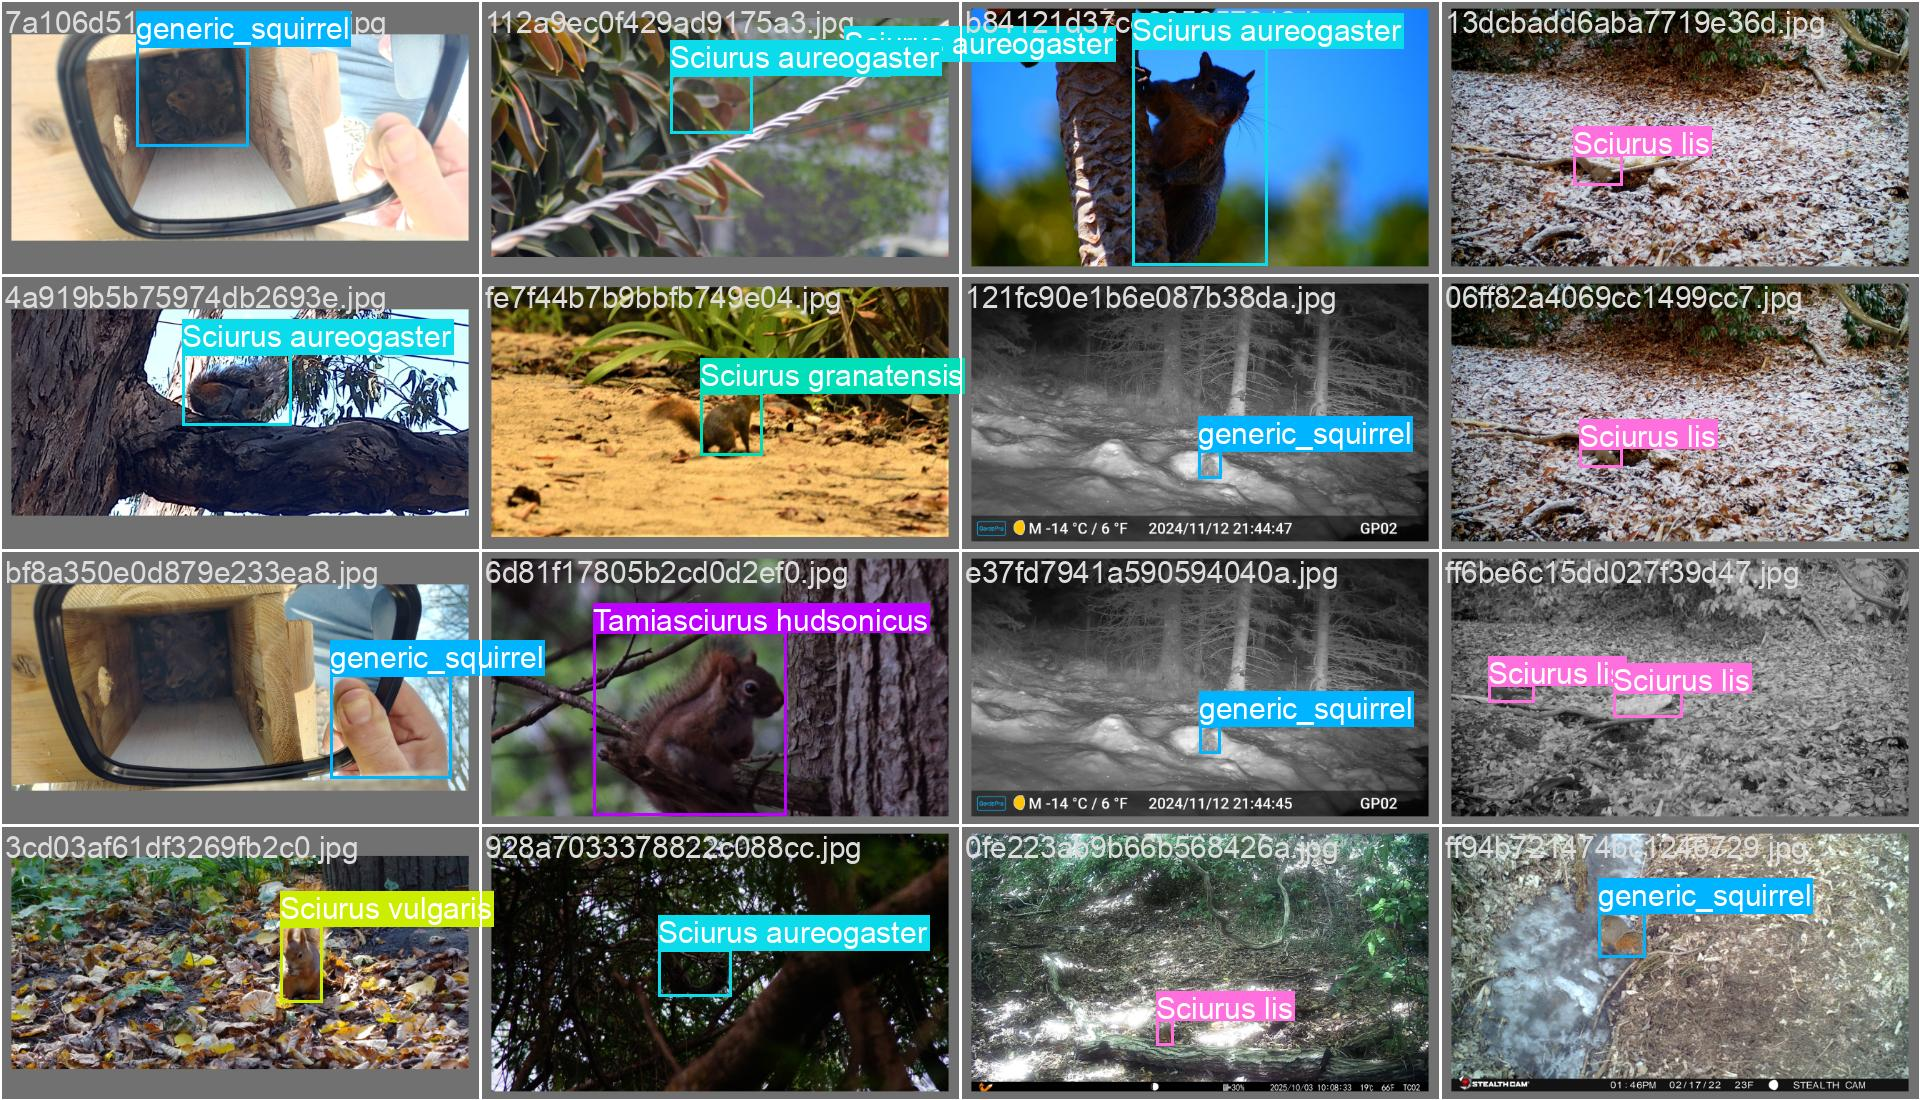

In [ ]:
from IPython.display import Image, display

display(Image(
    filename="/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_3epochs_retry/val_batch0_labels.jpg",
    width=900
))

In [ ]:
%cd /content/yolov5

!WANDB_MODE=disabled python train.py \
    --img 640 \
    --batch-size 8 \
    --epochs 10 \
    --data /content/squirrel-yolo/data.yaml \
    --weights yolov5m.pt \
    --device 0 \
    --workers 2 \
    --project /content/drive/MyDrive/YOLOv5_Squirrel_Training \
    --name squirrel_10epochs_fresh \
    --save-period 1

/content/yolov5
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791763578.877888   25280 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5m.pt, cfg=, data=/content/squirrel-yolo/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=10, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=/content/drive/MyDrive/YOLOv5_Squirrel_Training, name=squirrel_10epochs_fresh, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: u

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_10epochs_fresh/results.csv"

df = pd.read_csv(path)
df.columns = df.columns.str.strip()

columns = [
    "epoch",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

print(df[columns].tail(1).to_string(index=False))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_10epochs_fresh/results.csv'

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

path = Path(
    "/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_10epochs_fresh/results.csv"
)

print("Results file found:", path.is_file())

Mounted at /content/drive
Results file found: True


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/YOLOv5_Squirrel_Training/squirrel_10epochs_fresh/results.csv"

df = pd.read_csv(path)
df.columns = df.columns.str.strip()

columns = [
    "epoch",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

print(df[columns].tail(1).to_string(index=False))

 epoch  metrics/precision  metrics/recall  metrics/mAP_0.5  metrics/mAP_0.5:0.95
     9            0.61493         0.57149           0.5958               0.41294


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

print("Original dataset:",
      Path("/content/data/squirrel-v2-audited-coco").exists())

print("YOLO dataset:",
      Path("/content/squirrel-yolo/data.yaml").exists())

print("YOLOv5 installed:",
      Path("/content/yolov5/val.py").exists())

Original dataset: False
YOLO dataset: False
YOLOv5 installed: False


In [3]:
# Create the dataset folder
!mkdir -p /content/data

# Extract the squirrel dataset from Google Drive
!unzip -q "/content/drive/MyDrive/squirrel-v2-audited-coco.zip" -d /content/data

# Verify the dataset
!ls /content/data/squirrel-v2-audited-coco

decisions_applied.json	export_summary.json  test  train  valid


In [4]:
# Colab directory
%cd /content

# Downloading YOLOv5
!git clone https://github.com/ultralytics/yolov5.git

# Opening the YOLOv5 folder
%cd /content/yolov5

# Installing required libraries
!pip install -q -r requirements.txt

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (363/363), done.
remote: Compressing objects: 100% (212/212), done.
remote: Total 18806 (delta 303), reused 151 (delta 151), pack-reused 18443 (from 2)
Receiving objects: 100% (18806/18806), 17.72 MiB | 20.76 MiB/s, done.
Resolving deltas: 100% (12817/12817), done.
/content/yolov5


In [5]:
import json
import os
import shutil
from pathlib import Path
from collections import defaultdict

source = Path("/content/data/squirrel-v2-audited-coco/test")
output = Path("/content/squirrel-yolo")

image_dir = output / "images/test"
label_dir = output / "labels/test"

image_dir.mkdir(parents=True, exist_ok=True)
label_dir.mkdir(parents=True, exist_ok=True)

# Reading COCO annotations
with open(source / "_annotations.coco.json") as f:
    coco = json.load(f)

categories = sorted(coco["categories"], key=lambda c: c["id"])
class_map = {c["id"]: i for i, c in enumerate(categories)}

images = {img["id"]: img for img in coco["images"]}
labels = defaultdict(list)

# Converting bounding boxes to YOLO format
for ann in coco["annotations"]:
    img = images[ann["image_id"]]
    W, H = img["width"], img["height"]
    x, y, w, h = ann["bbox"]

    class_id = class_map[ann["category_id"]]

    xc = (x + w / 2) / W
    yc = (y + h / 2) / H

    labels[ann["image_id"]].append(
        f"{class_id} {xc:.8f} {yc:.8f} {w/W:.8f} {h/H:.8f}"
    )

# Preparing images and labels
for img in coco["images"]:
    filename = Path(img["file_name"])
    original = source / filename
    destination = image_dir / filename.name

    if not destination.exists():
        try:
            os.link(original, destination)
        except OSError:
            shutil.copy2(original, destination)

    label_file = label_dir / (filename.stem + ".txt")
    label_file.write_text(
        "\n".join(labels[img["id"]])
    )

print("Test images:", len(coco["images"]))
print("Bounding boxes:", len(coco["annotations"]))
print("Classes:", len(categories))
print("Test dataset preparation completed!")

Test images: 1284
Bounding boxes: 1380
Classes: 11
Test dataset preparation completed!


In [6]:
import json
import yaml
from pathlib import Path

source = Path("/content/data/squirrel-v2-audited-coco")
output = Path("/content/squirrel-yolo")

# Geting class names
with open(source / "test/_annotations.coco.json") as f:
    coco = json.load(f)

categories = sorted(coco["categories"], key=lambda c: c["id"])
class_names = [c["name"] for c in categories]

# Creating dataset configuration
config = {
    "path": str(output),
    "train": str(source / "train"),
    "val": str(source / "valid"),
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = output / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# Verifying test images and labels
test_images = list((output / "images/test").glob("*.jpg"))
test_labels = list((output / "labels/test").glob("*.txt"))

print("Configuration created:", yaml_path)
print("Test images: ", len(test_images))
print("Test labels:", len(test_labels))
print("Trained model available:", Path("/content/best.pt").is_file())

Configuration created: /content/squirrel-yolo/data.yaml
Test images:  1284
Test labels: 1284
Trained model available: True


In [7]:
%cd /content/yolov5

!python val.py \
    --weights /content/best.pt \
    --data /content/squirrel-yolo/data.yaml \
    --task test \
    --img 640 \
    --batch-size 8 \
    --device 0 \
    --workers 2 \
    --project /content/drive/MyDrive/YOLOv5_Squirrel_Test \
    --name squirrel_200epochs_test

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
val: data=/content/squirrel-yolo/data.yaml, weights=['/content/best.pt'], batch_size=8, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=0, workers=2, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/YOLOv5_Squirrel_Test, name=squirrel_200epochs_test, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-561-gaf08ba15 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 90 layers, 20,893,344 parameters, 0 gradients, 48.0 GFLOPs
100% 755k/755k [00:00<00:00, 209MB/s]
test: Scanning /content/squirrel-yolo/labels/test... 128